# Chapter 12 — Cross-Validation and Model Evaluation Techniques

**Reference:** *scikit-learn Cookbook, Third Edition* — John Sukup

This notebook covers K-fold and stratified CV, LOOCV, nested CV, metrics, learning curves, and generalizability.

## 1. Theory
A single train/test split can produce a noisy estimate. **K-fold CV** repeatedly trains on k−1 folds and validates on the remaining fold. **StratifiedKFold** preserves class proportions. **LOOCV** uses one sample per validation fold. **Nested CV** separates hyperparameter tuning from performance estimation. Keep a final test set untouched for final evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RANDOM_STATE = 42

from sklearn.datasets import make_classification, load_diabetes
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score, LeaveOneOut, GridSearchCV, learning_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, mean_squared_error
X,y=make_classification(n_samples=600,n_features=12,n_informative=7,n_redundant=2,weights=[.75,.25],random_state=RANDOM_STATE)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.25,stratify=y,random_state=RANDOM_STATE)
print("Class proportions:",pd.Series(y).value_counts(normalize=True).sort_index().round(3).to_dict())
model=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,random_state=RANDOM_STATE))


Class proportions: {0: 0.748, 1: 0.252}


## 2. K-fold versus Stratified K-fold

In [2]:

kf=KFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
skf=StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
a=cross_val_score(model,X_train,y_train,cv=kf,scoring="accuracy")
b=cross_val_score(model,X_train,y_train,cv=skf,scoring="accuracy")
display(pd.DataFrame({"KFold":a,"StratifiedKFold":b},index=[f"Fold {i}" for i in range(1,6)]).round(3))
print("Mean accuracies:",round(a.mean(),3),round(b.mean(),3))


,KFold,StratifiedKFold
Fold 1,0.856,0.867
Fold 2,0.956,0.967
Fold 3,0.867,0.922
Fold 4,0.922,0.922
Fold 5,0.900,0.856


Mean accuracies: 0.9 0.907


## 3. Classification metrics

In [3]:

model.fit(X_train,y_train); pred=model.predict(X_test); prob=model.predict_proba(X_test)[:,1]
metrics={"Accuracy":accuracy_score(y_test,pred),"Precision":precision_score(y_test,pred,zero_division=0),
"Recall":recall_score(y_test,pred,zero_division=0),"F1":f1_score(y_test,pred,zero_division=0),"ROC AUC":roc_auc_score(y_test,prob)}
display(pd.DataFrame.from_dict(metrics,orient="index",columns=["Score"]).round(3))
print("Confusion matrix:\n",confusion_matrix(y_test,pred))


,Score
Accuracy,0.913
Precision,0.931
Recall,0.711
F1,0.806
ROC AUC,0.913


Confusion matrix:
 [[110   2]
 [ 11  27]]


Accuracy measures overall correctness; precision measures how many predicted positives are correct; recall measures how many actual positives are found; F1 balances precision and recall; ROC AUC evaluates ranking across thresholds.

## 4. LOOCV and nested cross-validation

In [4]:

diabetes=load_diabetes(); Xd,yd=diabetes.data,diabetes.target
loo=cross_val_score(Ridge(alpha=1),Xd[:80],yd[:80],cv=LeaveOneOut(),scoring="neg_mean_squared_error")
print("LOOCV RMSE on 80 diabetes samples:",round(np.sqrt(-loo.mean()),3))
outer=KFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
inner=KFold(n_splits=3,shuffle=True,random_state=RANDOM_STATE)
ridge=make_pipeline(StandardScaler(),Ridge())
mse=[]
for tr,va in outer.split(Xd):
    search=GridSearchCV(ridge,{"ridge__alpha":[.01,.1,1,10,100]},cv=inner,scoring="neg_mean_squared_error",n_jobs=-1)
    search.fit(Xd[tr],yd[tr]); mse.append(mean_squared_error(yd[va],search.predict(Xd[va])))
print("Nested CV RMSE by fold:",np.round(np.sqrt(mse),2))
print("Mean nested CV RMSE:",round(np.sqrt(mse).mean(),2))


LOOCV RMSE on 80 diabetes samples: 65.916


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Nested CV RMSE by fold: [53.85 51.93 58.   53.   58.34]
Mean nested CV RMSE: 55.02


## 5. Learning curve and final test score

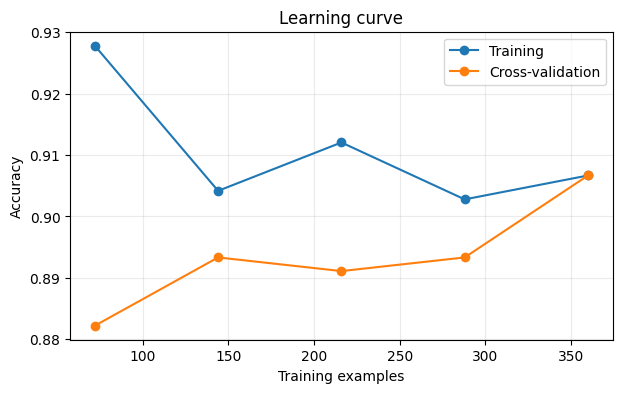

Held-out test accuracy: 0.913


In [5]:

sizes,train_scores,val_scores=learning_curve(model,X_train,y_train,cv=skf,scoring="accuracy",train_sizes=np.linspace(.2,1,5),n_jobs=-1)
plt.figure(figsize=(7,4)); plt.plot(sizes,train_scores.mean(axis=1),marker="o",label="Training")
plt.plot(sizes,val_scores.mean(axis=1),marker="o",label="Cross-validation")
plt.xlabel("Training examples"); plt.ylabel("Accuracy"); plt.title("Learning curve"); plt.legend(); plt.grid(alpha=.25); plt.show()
model.fit(X_train,y_train); print("Held-out test accuracy:",round(accuracy_score(y_test,model.predict(X_test)),3))


## Exercises
1. Compare 3-, 5-, and 10-fold CV.
2. Compare KFold and StratifiedKFold for imbalanced classes.
3. Explain why tuning and final evaluation should be separated.
4. Compare RMSE, MAE, and R² on a regression task.
5. Interpret the learning curve.

## Summary
Cross-validation estimates generalization across different splits. Stratification helps preserve class balance, and nested CV separates tuning from performance estimation. Select task-appropriate metrics and keep test data separate.